## Notebook to visualize attention between 2 graphs

In [100]:
import sys, os, glob
sys.path.insert(0, os.path.abspath('src'))  

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import seaborn as sns
import pandas as pd

from src.graphmatchingnetwork import GraphMatchingNetwork

In [101]:
# --- Configurazione ---
CHECKPOINT    = "lightning_logs/gmn_model/version_1/best.ckpt"
PROCESSED_DIR = "data/processed"
CSV_PATH = "data/raw/PL_cleaned_index.csv"

# Scegli il complesso da visualizzare
pt_files  = glob.glob(os.path.join(PROCESSED_DIR, "protein_*.pt"))
pdb_codes = sorted([os.path.basename(f).replace("protein_", "").replace(".pt", "") for f in pt_files])
print(f"Complessi disponibili: {len(pdb_codes)}")

PDB_CODE = pdb_codes[5]   # ← cambia qui per un complesso diverso
print(f"Complesso selezionato: {PDB_CODE}")

Complessi disponibili: 4851
Complesso selezionato: 1a08


In [102]:
# --- Carica modello dal checkpoint ---
model = GraphMatchingNetwork.load_from_checkpoint(CHECKPOINT, map_location='cpu')
model.eval()
print(dict(model.hparams))

{'token_dim': 16, 'node_embedding_dims': [48], 'edge_embedding_dims': [32], 'num_layers': 1, 'lr': 1e-05, 'dropout_p': 0.0, 'normalization': True}


In [103]:
# --- Carica il complesso scelto ---
prot = torch.load(os.path.join(PROCESSED_DIR, f"protein_{PDB_CODE}.pt"), weights_only=False)
lig  = torch.load(os.path.join(PROCESSED_DIR, f"ligand_{PDB_CODE}.pt"),  weights_only=False)


# Batch vector: un solo grafo (tutti zero) - simulo una batch 
prot.batch = torch.zeros(prot.x.shape[0], dtype=torch.long)
lig.batch  = torch.zeros(lig.x.shape[0],  dtype=torch.long)

n_prot = prot.x.shape[0]
n_lig  = lig.x.shape[0]
print(f"Proteina : {n_prot} residui | {prot.edge_index.shape[1]//2} archi")
print(f"Ligando  : {n_lig} atomi   | {lig.edge_index.shape[1]//2} archi")
print(f"pAffinity: {prot.y.item():.3f}")

Proteina : 105 residui | 580 archi
Ligando  : 41 atomi   | 272 archi
pAffinity: 5.620


In [104]:
#grafo proteina
from src.protein import Protein

protein = Protein.from_pdb_code(PDB_CODE)
protein.visualize_protein_graph()

Output()

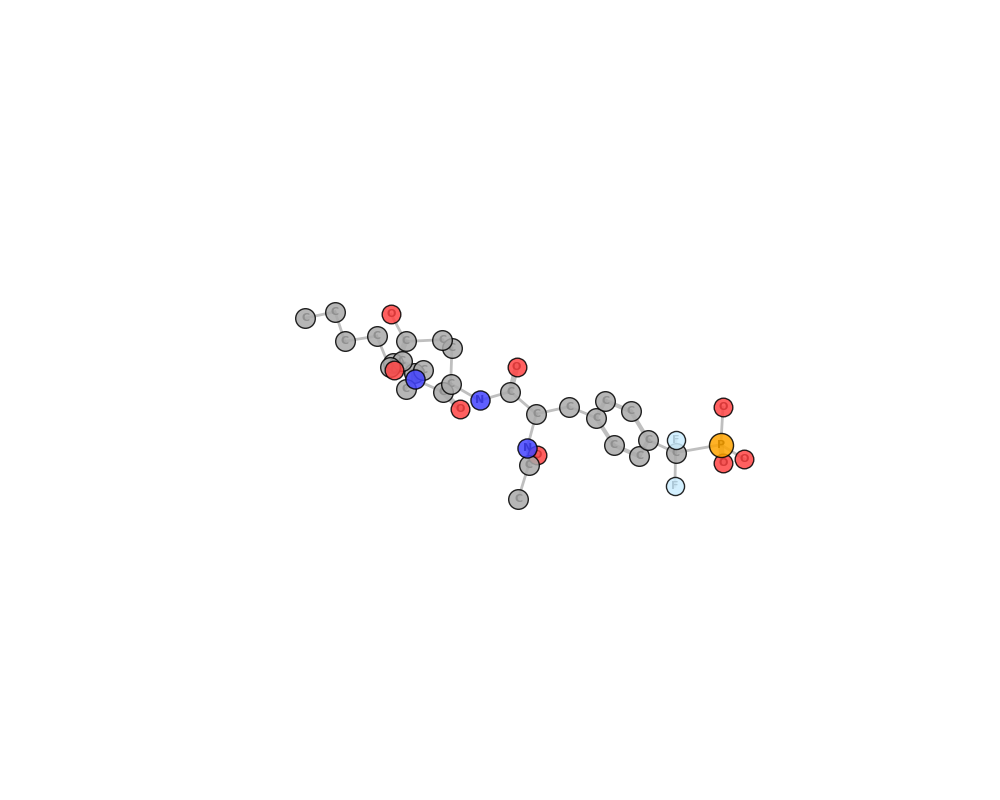

In [105]:
#grafo ligando
from src.ligand import Ligand
df=pd.read_csv(CSV_PATH)
smile=df[df['pdb_code']==PDB_CODE]['SMILE'].values[0]
smile
ligand=Ligand.from_smile(smiles=smile)
ligand.visualize_nx3D()

In [106]:
# --- Inference + estrazione attention ---
with torch.no_grad():
    pred, (attn_p_to_l, attn_l_to_p) = model(prot, lig, return_attention=True)

# Rimuovi dim batch (B=1), converti in numpy
attn_p_to_l = attn_p_to_l[0].numpy()   # [N_prot, N_lig]
attn_l_to_p = attn_l_to_p[0].numpy()   # [N_lig,  N_prot]

print(f"Predizione pAffinity : {pred.item():.3f}")
print(f"Reale pAffinity      : {prot.y.item():.3f}")
print(f"attn_p_to_l : {attn_p_to_l.shape}  (somma righe ≈ 1: {attn_p_to_l.sum(axis=1).mean():.3f})")
print(f"attn_l_to_p : {attn_l_to_p.shape}")

Predizione pAffinity : 6.912
Reale pAffinity      : 5.620
attn_p_to_l : (105, 41)  (somma righe ≈ 1: 1.000)
attn_l_to_p : (41, 105)


In [107]:
# --- Etichette nodi ---
AMINO_ACIDS = ['ALA','ARG','ASN','ASP','CYS','GLN','GLU','GLY','HIS','ILE',
               'LEU','LYS','MET','PHE','PRO','SER','THR','TRP','TYR','VAL','UNK']

ATOMIC_SYM  = {1:'H',6:'C',7:'N',8:'O',9:'F',15:'P',16:'S',17:'Cl',35:'Br',53:'I'}

#label protein - SER0 ILE1 GLN2
aa_codes  = prot.x[:, 8].long().tolist()
prot_labels = [f"{AMINO_ACIDS[min(c, 20)]}{i}" for i, c in enumerate(aa_codes)]

#label ligand - O0 C1 C3 P4
atom_nums = lig.x[:, 0].long().tolist()
lig_labels  = [f"{ATOMIC_SYM.get(n, f'Z{n}')}{i}" for i, n in enumerate(atom_nums)]

print("Primi 5 residui :", prot_labels[:5])
print("Primi 5 atomi   :", lig_labels[:5])

Primi 5 residui : ['SER0', 'ILE1', 'GLN2', 'ALA3', 'GLU4']
Primi 5 atomi   : ['O0', 'C1', 'C2', 'P3', 'F4']


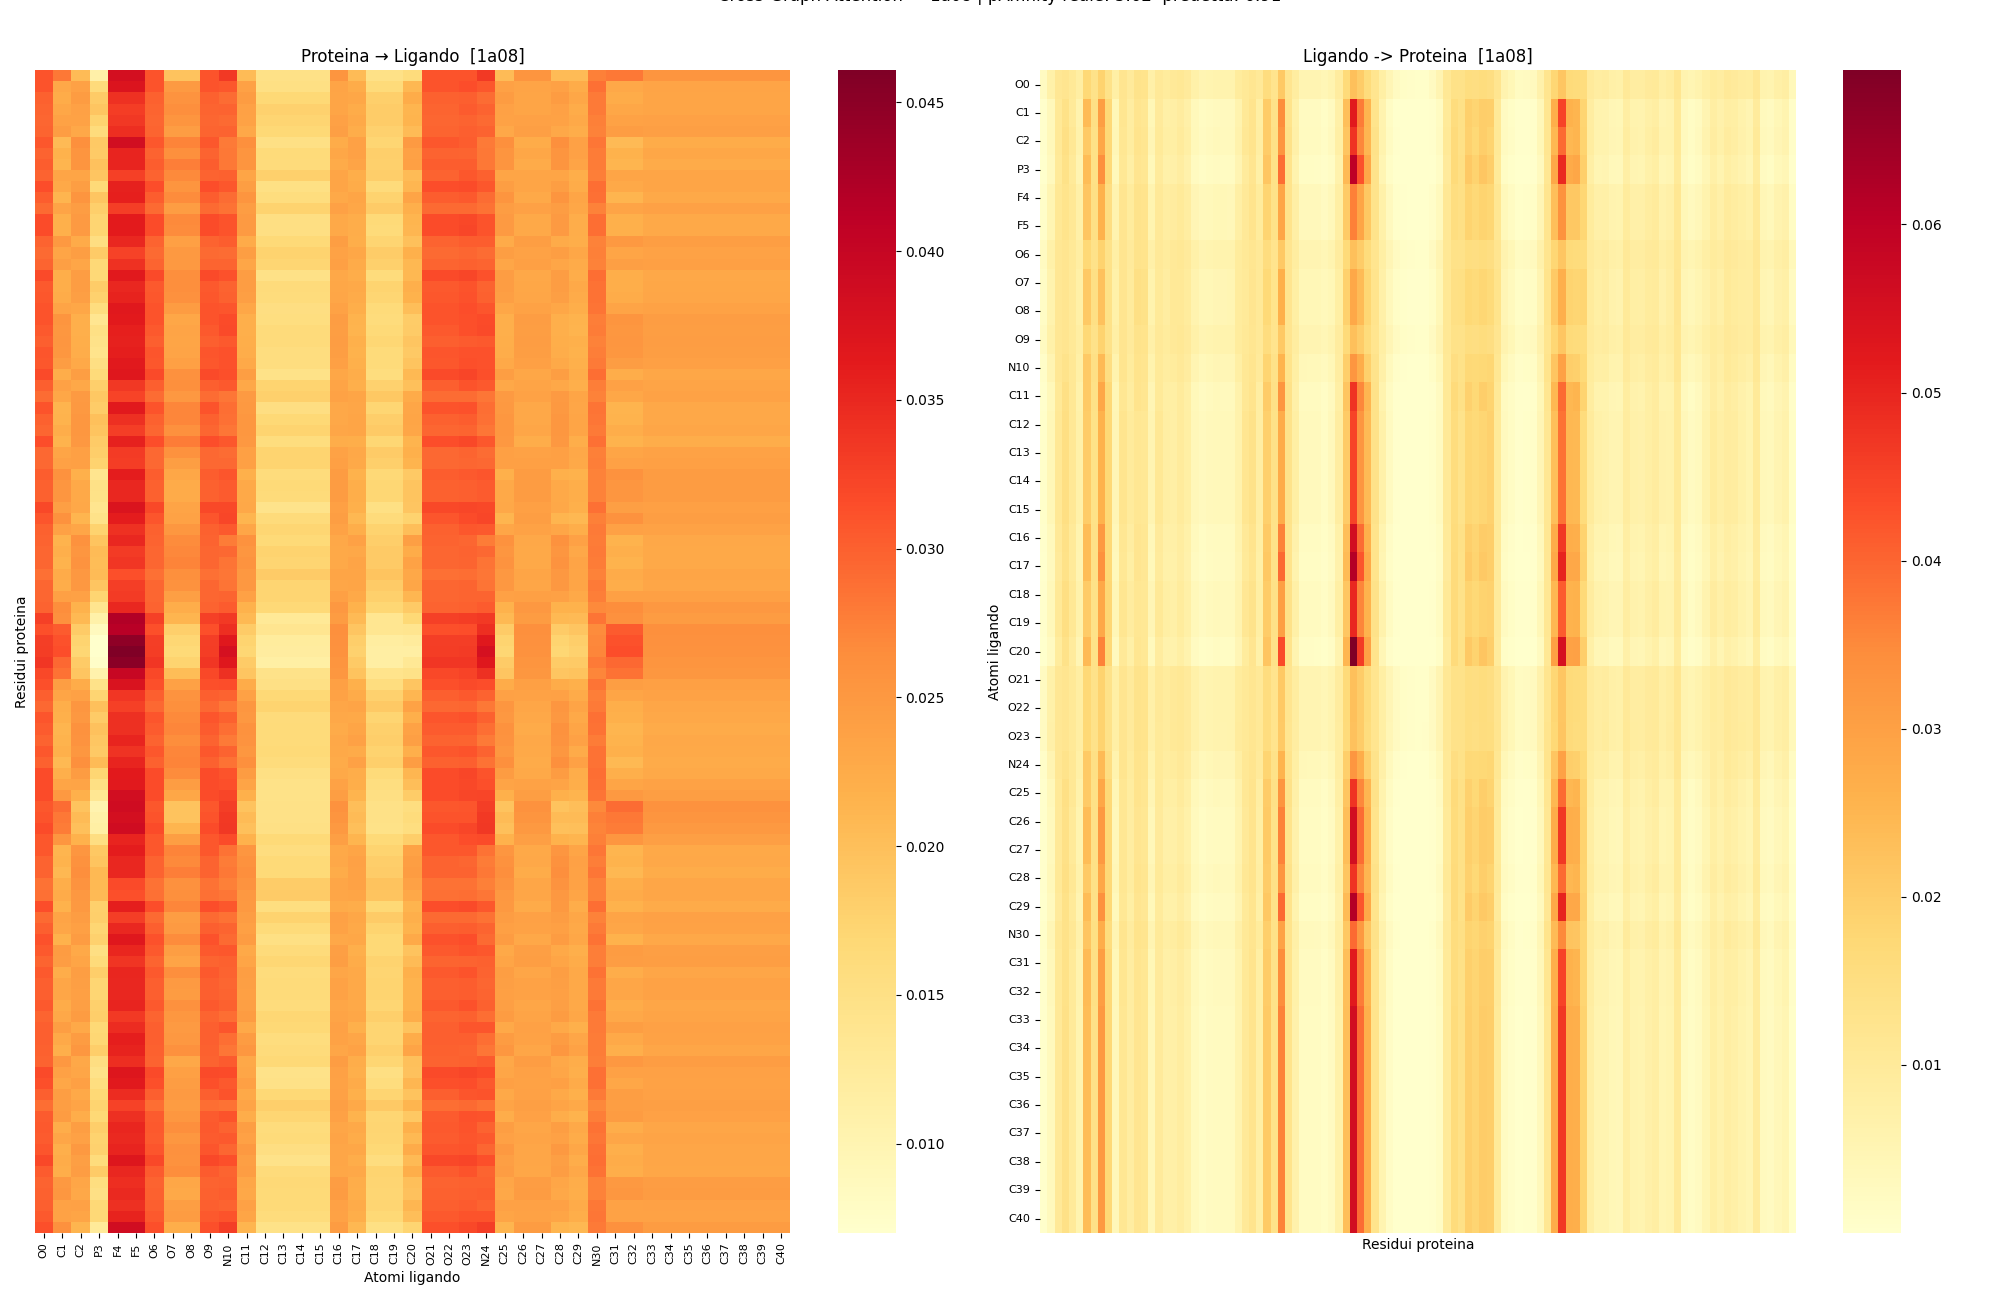

In [110]:
# --- Heatmap bidirezionale ---
fig, axes = plt.subplots(1, 2, figsize=(20, max(6, n_prot // 8)))

# Proteina → Ligando  [N_prot × N_lig]
ax = axes[0]
sns.heatmap(attn_p_to_l, ax=ax, cmap='YlOrRd', cbar=True,
            xticklabels=lig_labels,
            yticklabels=prot_labels if n_prot <= 80 else False)
ax.set_xlabel('Atomi ligando')
ax.set_ylabel('Residui proteina')
ax.set_title(f'Proteina → Ligando  [{PDB_CODE}]')
ax.tick_params(axis='x', labelsize=8, rotation=90)
ax.tick_params(axis='y', labelsize=6)

# Ligando → Proteina  [N_lig × N_prot]
ax = axes[1]
sns.heatmap(attn_l_to_p, ax=ax, cmap='YlOrRd', cbar=True,
            xticklabels=prot_labels if n_prot <= 80 else False,
            yticklabels=lig_labels)
ax.set_xlabel('Residui proteina')
ax.set_ylabel('Atomi ligando')
ax.set_title(f'Ligando -> Proteina  [{PDB_CODE}]')
ax.tick_params(axis='x', labelsize=6, rotation=90)
ax.tick_params(axis='y', labelsize=8)

plt.suptitle(
    f'Cross-Graph Attention — {PDB_CODE} | pAffinity reale: {prot.y.item():.2f}  predetta: {pred.item():.2f}',
    fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig(f'attention_{PDB_CODE}_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

256 archi visualizzati (su 4305 totali)


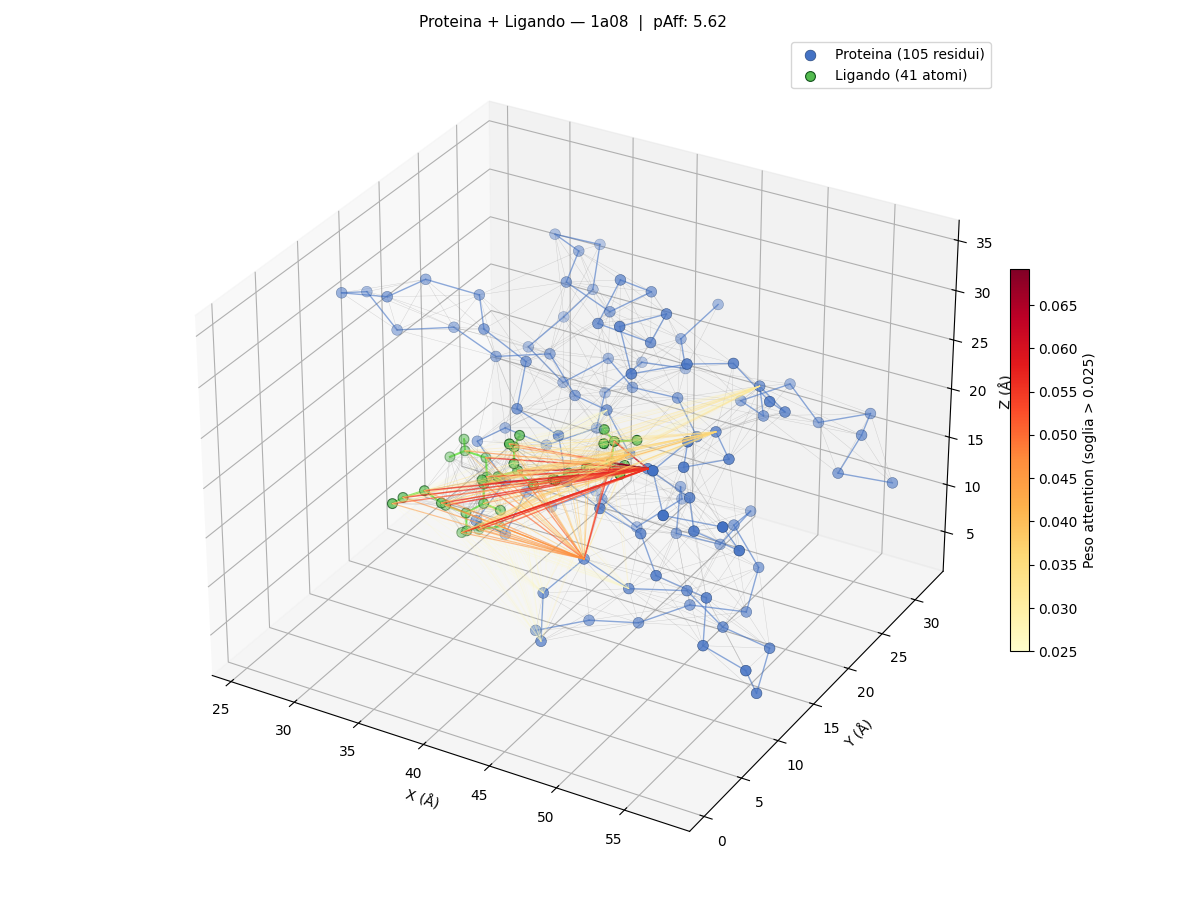

In [109]:
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

pos_prot = prot.pos.numpy()   # [N_prot, 3]
pos_lig  = lig.pos.numpy()    # [N_lig,  3]

fig = plt.figure(figsize=(12, 9))
ax  = fig.add_subplot(111, projection='3d')

# --- Proteina: cerchi blu ---
ax.scatter(pos_prot[:, 0], pos_prot[:, 1], pos_prot[:, 2],
           c='#4472C4', s=60, edgecolors='#1a3a6e', linewidths=0.4,
           depthshade=True, label=f'Proteina ({n_prot} residui)', zorder=2)

seen = set()
for k, (src, dst) in enumerate(prot.edge_index.t().numpy()):
    e = tuple(sorted((int(src), int(dst))))
    if e in seen:
        continue
    seen.add(e)
    p1, p2 = pos_prot[src], pos_prot[dst]
    if prot.edge_attr[k, 0].item() == 1.0:   # peptide bond → linea visibile
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                color="#4473C4C2", linewidth=1, alpha=0.6)
    else:                                      # contatto spaziale → quasi invisibile
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                color="#929191", linewidth=0.3, alpha=0.4)

# --- Ligando: cerchi verdi ---
ax.scatter(pos_lig[:, 0], pos_lig[:, 1], pos_lig[:, 2],
           c="#53BB4F", s=50, edgecolors="#13521C", linewidths=0.8,
           marker='o', depthshade=True, label=f'Ligando ({n_lig} atomi)', zorder=3)

seen_l = set()
for k, (src, dst) in enumerate(lig.edge_index.t().numpy()):
    e = tuple(sorted((int(src), int(dst))))
    if e in seen_l:
        continue
    seen_l.add(e)
    p1, p2 = pos_lig[src], pos_lig[dst]
    if lig.edge_attr[k, 0] != 0.0:
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                color="#4CDF1F", linewidth=1.5, alpha=0.7)
    else:
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                color="#929191", linewidth=0.3, alpha=0.4)

# --- Archi attention sopra soglia ---
THRESHOLD = 0.025
edge_pairs, edge_weights_all = [], []
for j in range(n_lig):
    for i in range(n_prot):
        w = float(attn_l_to_p[j, i])
        if w > THRESHOLD:
            edge_pairs.append((i, j))
            edge_weights_all.append(w)

if edge_pairs:
    norm     = Normalize(vmin=THRESHOLD, vmax=max(edge_weights_all))
    cmap_att = plt.cm.YlOrRd
    for (i, j), w in zip(edge_pairs, edge_weights_all):
        p1, p2 = pos_prot[i], pos_lig[j]
        color  = cmap_att(norm(w))
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]],
                color=color, linewidth=0.5 + 0.8 * norm(w),
                alpha=0.2 + 0.8 * norm(w), zorder=4)
    sm = ScalarMappable(cmap=cmap_att, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.45, pad=0.01,
                 label=f'Peso attention (soglia > {THRESHOLD})')
    print(f"{len(edge_pairs)} archi visualizzati (su {n_prot * n_lig} totali)")
else:
    print(f"Nessun arco sopra soglia {THRESHOLD} — prova ad abbassarla")

# --- Aspect ratio reale ---
all_pos   = np.vstack([pos_prot, pos_lig])
max_range = (all_pos.max(axis=0) - all_pos.min(axis=0)).max() / 2.0
mid       = (all_pos.max(axis=0) + all_pos.min(axis=0)) / 2.0
ax.set_xlim(mid[0]-max_range, mid[0]+max_range)
ax.set_ylim(mid[1]-max_range, mid[1]+max_range)
ax.set_zlim(mid[2]-max_range, mid[2]+max_range)

ax.set_title(f'Proteina + Ligando — {PDB_CODE}  |  pAff: {prot.y.item():.2f}', fontsize=11)
ax.set_xlabel('X (Å)'); ax.set_ylabel('Y (Å)'); ax.set_zlabel('Z (Å)')
ax.legend(fontsize=10, markerscale=1.0)
plt.tight_layout()
plt.show()